# <div style="background: linear-gradient(135deg, #6e8efb, #a777e3);padding: 30px;border-radius: 15px;box-shadow: 0 4px 15px rgba(0,0,0,0.2);text-align: center;color: white;font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;"><h1 style="margin: 0; font-size: 40px; border: none; color: white;">Задание по недвижимости</h1><p style="margin: 10px 0 0; font-size: 18px; opacity: 0.9; text-align:center"></p></div>

In [2]:
# импорт библиотек

In [1]:
import joblib
import json
import numpy as np
import pandas as pd

In [3]:
model = joblib.load('final_model.pkl')
meta = json.load(open('model_meta.json', encoding='utf-8'))
print("Описание модели")
print(f"Алгоритм:      {meta['model_name']}")
print(f"Целевая:       {meta['target']}")
print(f"Признаков:     {len(meta['features'])}")
print("\nМетрики на валидации ")
for k, v in meta['metrics'].items():
    if isinstance(v, float):
        print(f"{k:6s} = {v:,.4f}")
    else:
        print(f"{k:6s} = {v}")

Описание модели
Алгоритм:      LightGBM
Целевая:       price
Признаков:     123

Метрики на валидации 
MAE    = 75,744.7919
RMSE   = 193,183.4122
MAPE   = 50.8913
R2     = 0.7820


In [5]:
# Создал копию тестовых данных
y_true = test_df['price'].values if 'price' in test_df.columns else None
ids = test_df['id'].values if 'id' in test_df.columns else np.arange(len(test_df))
X = test_df.copy()
X = X.drop(columns=['id', 'price', 'price_currency', 'type', 'furnished', 'end_date'],
           errors='ignore')

In [6]:
# building_age → число
age_map = {'0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5,
           '6-10 arası': 8, '11-15 arası': 13, '16-20 arası': 18,
           '21-25 arası': 23, '26-30 arası': 28, '31 ve üzeri': 35}
if 'building_age' in X.columns:
    X['building_age_num'] = X['building_age'].map(age_map)
    X = X.drop(columns=['building_age'])

# total_floor_count → число
floor_map = {'1': 1, '2': 2, '3': 3, '4': 4, '5': 5, '6': 6, '7': 7, '8': 8, '9': 9,
             '10-20 arası': 15, '20 ve üzeri': 25, 'Müstakil': 1}
if 'total_floor_count' in X.columns:
    X['total_floor_num'] = X['total_floor_count'].map(floor_map)
    X = X.drop(columns=['total_floor_count'])

# floor_no → число
def parse_floor(x):
    x = str(x).strip()
    if x.isdigit():
        return int(x)
    special = {'Yüksek Giriş': 1, 'Giriş': 0, 'Kot 1': -1, 'Kot 2': -2,
               'Asma Kat': 1, 'Müstakil': 1, 'Çatı Katı': 99,
               'Bahçe katı': 0, 'Zemin Kat': 0, 'Giriş Katı': 0,
               'En Üst Kat': 99, 'Teras Kat': 99, 'Bodrum Kat': -1,
               'Kot 3': -3, 'Kot 4': -4, 'Komple': 1, '20 ve üzeri': 25}
    return special.get(x, np.nan)

if 'floor_no' in X.columns:
    X['floor_num'] = X['floor_no'].apply(parse_floor)
    X = X.drop(columns=['floor_no'])

# room_count → 2 признака
def parse_rooms(x):
    parts = str(x).replace(' ', '').split('+')
    try:
        return int(parts[0]), int(parts[1]) if len(parts) > 1 else 0
    except Exception:
        return np.nan, np.nan

if 'room_count' in X.columns:
    X[['rooms_living', 'rooms_extra']] = X['room_count'].apply(
        lambda x: pd.Series(parse_rooms(x)))
    X = X.drop(columns=['room_count'])

# start_date → год, месяц, день
if 'start_date' in X.columns:
    X['start_date'] = pd.to_datetime(X['start_date'], format='%m/%d/%y', errors='coerce')
    X['start_year']  = X['start_date'].dt.year
    X['start_month'] = X['start_date'].dt.month
    X['start_dow']   = X['start_date'].dt.dayofweek
    X = X.drop(columns=['start_date'])

# address → city / district
if 'address' in X.columns:
    addr_split = X['address'].str.split('/', n=2, expand=True)
    X['city']     = addr_split[0].str.strip()
    X['district'] = addr_split[1].fillna('Unknown').str.strip()
    X = X.drop(columns=['address'])

# Feature Engineering
X['floor_ratio']   = X['floor_num'] / X['total_floor_num'].replace(0, 1)
X['rooms_total']   = X['rooms_living'] + X['rooms_extra']
X['size_per_room'] = X['size'] / X['rooms_total'].replace(0, 1)


In [7]:
# Восстанавил smooth из исходника так как без него наш топ 1 признак destrict_te невозможно будет восстановить точно
df_orig = pd.read_csv('real_estate_data.csv', sep=',', low_memory=False)
df_orig = df_orig[df_orig['price_currency'] == 'TRY']
df_orig = df_orig[df_orig['price'] > 0]
df_orig['price_log'] = np.log1p(df_orig['price'])

addr = df_orig['address'].str.split('/', n=2, expand=True)
df_orig['district'] = addr[1].fillna('Unknown').str.strip()

prior = df_orig['price_log'].mean()
m = 10
agg = df_orig.groupby('district')['price_log'].agg(['mean', 'count'])
agg = agg[agg['count'] >= 5]
smooth = (agg['mean'] * agg['count'] + prior * m) / (agg['count'] + m)


In [8]:
# Применил target encoding
X['district_te'] = X['district'].map(smooth).fillna(prior)
X = X.drop(columns=['district'])
print(f"district_te: min={X['district_te'].min():.2f}, max={X['district_te'].max():.2f}")
print(f"prior = {prior:.4f}")

district_te: min=10.03, max=12.57
prior = 11.0295


In [9]:
# One-Hot для sub_type, heating_type, city
X = pd.get_dummies(X, columns=['sub_type', 'heating_type', 'city'],
                   drop_first=True, dtype=int)

In [10]:
# Привёл колонки к тем что ожидает модель
expected_cols = meta['features']

for col in expected_cols:
    if col not in X.columns:
        X[col] = 0

X = X[expected_cols]

print(f"X: {X.shape}  (ожидается {len(expected_cols)} колонок)")

X: (20, 123)  (ожидается 123 колонок)


/tmp/ipykernel_23986/791514479.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[col] = 0
/tmp/ipykernel_23986/791514479.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[col] = 0
/tmp/ipykernel_23986/791514479.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[col] = 0


In [22]:
# Прогноз
y_pred_log = model.predict(X)
y_pred = np.clip(np.expm1(y_pred_log), 0, None)

print(f"\nПрогнозы: {y_pred[:5].round(0)}")


Прогнозы: [ 176851. 1156531.  221593.   86664.  170348.]


In [16]:
result = test_df.copy()
result['predicted_price'] = y_pred.round(0)

In [17]:
if 'price' in test_df.columns:
    result['actual_price'] = test_df['price']
    result['error'] = (result['actual_price'] - result['predicted_price']).round(0)
    result['error_%'] = (result['error'] / result['actual_price'] * 100).round(2)

In [19]:
result['ФИО'] = 'Ахмадуллин Вадим Ринатович'
result['Группа'] = '23П-4'

In [20]:
print(result[['id', 'predicted_price', 'actual_price', 'error', 'error_%', 'ФИО', 'Группа']]
      .to_string(index=False))

   id  predicted_price  actual_price     error  error_%                        ФИО Группа
   49         176851.0      300000.0  123149.0    41.05 Ахмадуллин Вадим Ринатович  23П-4
  506        1156531.0     1600000.0  443469.0    27.72 Ахмадуллин Вадим Ринатович  23П-4
    2         221593.0      490000.0  268407.0    54.78 Ахмадуллин Вадим Ринатович  23П-4
  528          86664.0      103600.0   16936.0    16.35 Ахмадуллин Вадим Ринатович  23П-4
  109         170348.0      300000.0  129652.0    43.22 Ахмадуллин Вадим Ринатович  23П-4
  100         356493.0      500000.0  143507.0    28.70 Ахмадуллин Вадим Ринатович  23П-4
  320         536287.0     1000000.0  463713.0    46.37 Ахмадуллин Вадим Ринатович  23П-4
    3         149821.0      155000.0    5179.0     3.34 Ахмадуллин Вадим Ринатович  23П-4
 7810         636950.0      650000.0   13050.0     2.01 Ахмадуллин Вадим Ринатович  23П-4
   11        1389973.0     2450000.0 1060027.0    43.27 Ахмадуллин Вадим Ринатович  23П-4
    1     

In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
if 'actual_price' in result.columns:
    y_true = result['actual_price'].values
    y_pred_arr = result['predicted_price'].values
    
    n = len(y_true)
    mae_m  = np.sum(np.abs(y_true - y_pred_arr)) / n
    mse_m  = np.sum((y_true - y_pred_arr) ** 2) / n
    rmse_m = np.sqrt(mse_m)
    ss_res = np.sum((y_true - y_pred_arr) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2_m   = 1 - ss_res / ss_tot

    print("считаю вручную")
    print(f"MAE  = {mae_m:,.2f}")
    print(f"RMSE = {rmse_m:,.2f}")
    print(f"R²   = {r2_m:.4f}")

    # sklearn
    mae_s  = mean_absolute_error(y_true, y_pred_arr)
    rmse_s = np.sqrt(mean_squared_error(y_true, y_pred_arr))
    r2_s   = r2_score(y_true, y_pred_arr)

    print("\n Sklearn")
    print(f"MAE  = {mae_s:,.2f}")
    print(f"RMSE = {rmse_s:,.2f}")
    print(f"R²   = {r2_s:.4f}")

    metrics_table = pd.DataFrame({
        'Метрика': ['MAE', 'RMSE', 'R²'],
        'Вручную': [mae_m, rmse_m, r2_m],
        'Sklearn': [mae_s, rmse_s, r2_s],
        'Совпадение': [
            np.isclose(mae_m, mae_s),
            np.isclose(rmse_m, rmse_s),
            np.isclose(r2_m, r2_s)
        ]
    })
    print(metrics_table.to_string(index=False))
else:
    print("ОШибка")

считаю вручную
MAE  = 135,715.75
RMSE = 288,187.09
R²   = 0.7868

 Sklearn
MAE  = 135,715.75
RMSE = 288,187.09
R²   = 0.7868
Метрика       Вручную       Sklearn  Совпадение
    MAE 135715.750000 135715.750000        True
   RMSE 288187.089446 288187.089446        True
     R²      0.786773      0.786773        True


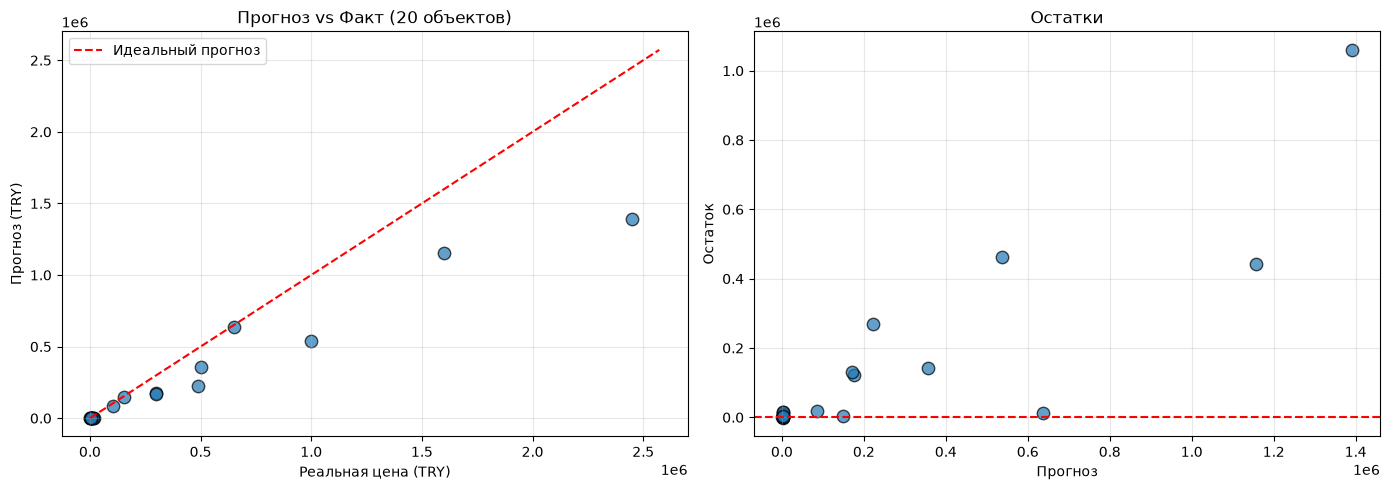


Топ 5 ошибок 
 id  actual_price  predicted_price     error  error_%
 11     2450000.0        1389973.0 1060027.0    43.27
320     1000000.0         536287.0  463713.0    46.37
506     1600000.0        1156531.0  443469.0    27.72
  2      490000.0         221593.0  268407.0    54.78
100      500000.0         356493.0  143507.0    28.70

Средняя ошибка в %: 48.68%
Медианная ошибка:   13,614 TRY


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'actual_price' in result.columns:
    y_true = result['actual_price'].values
    y_pred_arr = result['predicted_price'].values
    residuals = y_true - y_pred_arr
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].scatter(y_true, y_pred_arr, alpha=0.7, s=80, edgecolor='black')
    lims = [min(y_true.min(), y_pred_arr.min()) * 0.9,
            max(y_true.max(), y_pred_arr.max()) * 1.05]
    axes[0].plot(lims, lims, 'r--', label='Идеальный прогноз')
    axes[0].set_xlabel('Реальная цена (TRY)')
    axes[0].set_ylabel('Прогноз (TRY)')
    axes[0].set_title('Прогноз vs Факт')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Остатки
    axes[1].scatter(y_pred_arr, residuals, alpha=0.7, s=80, edgecolor='black')
    axes[1].axhline(0, color='r', ls='--')
    axes[1].set_xlabel('Прогноз')
    axes[1].set_ylabel('Остаток')
    axes[1].set_title('Остатки')
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('test_results.png', dpi=120)
    plt.show()

    result['abs_error'] = np.abs(result['error'])
    print("\nТоп 5 ошибок ")
    print(result.nlargest(5, 'abs_error')[
        ['id', 'actual_price', 'predicted_price', 'error', 'error_%']
    ].to_string(index=False))

    # Средняя ошибка
    print(f"\nСредняя ошибка в %: {result['error_%'].abs().mean():.2f}%")
    print(f"Медианная ошибка:   {result['error'].abs().median():,.0f} TRY")

In [21]:
result.to_csv('result_real_estate_samples.csv', index=False)


Сохранено: result_real_estate_samples.csv


модель пригодна для прогноза в диапазоне гдето 100 000 до 1 000 000 TRY но не подходит для элитной недвижимости

### Итог:
- Проделано работа по недвижимости
- Выполнены все 4 пункта
- Средняя ошибка в %: 48.68%
- Медианная ошибка:   13,614 TRY
- Всю работу сохранил в файл result_real_estate_samples.csv